In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [52]:
data='https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
# !wget $data -O data-week-3.csv

In [53]:
df = pd.read_csv('data-week-3.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [54]:
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.lower().str.strip().str.replace(' ', '_')
df.columns=df.columns.str.lower().str.replace(' ','_')
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [55]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [56]:
category=[i for i in df.columns[df.dtypes =='object']]
category
numirical=[i for i in df.columns[df.dtypes != 'object']]

df[category].isnull

<bound method DataFrame.isnull of          lead_source       industry employment_status       location
0     organic_search     technology          employed         europe
1       social_media     technology          employed  south_america
2           referral         retail          employed         europe
3           paid_ads  manufacturing           student            NaN
4           referral  manufacturing           student  north_america
...              ...            ...               ...            ...
4995  organic_search      education          employed           asia
4996             NaN     technology          employed  north_america
4997  organic_search        finance          employed           asia
4998        referral     technology          employed         africa
4999        referral     technology          employed         europe

[5000 rows x 4 columns]>

In [57]:
df[category] = df[category].fillna('NA')
df[numirical] = df[numirical].fillna(0)
df[category].isnull ,df[numirical].isnull()

(<bound method DataFrame.isnull of          lead_source       industry employment_status       location
 0     organic_search     technology          employed         europe
 1       social_media     technology          employed  south_america
 2           referral         retail          employed         europe
 3           paid_ads  manufacturing           student             NA
 4           referral  manufacturing           student  north_america
 ...              ...            ...               ...            ...
 4995  organic_search      education          employed           asia
 4996              NA     technology          employed  north_america
 4997  organic_search        finance          employed           asia
 4998        referral     technology          employed         africa
 4999        referral     technology          employed         europe
 
 [5000 rows x 4 columns]>,
       annual_income  number_of_courses_viewed  interaction_count  lead_score  \
 0             F

In [58]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [59]:
from sklearn.metrics import roc_auc_score

In [60]:
y_train=df_train.converted
y_val=df_val.converted
y_test=df_test.converted
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [63]:
numirical.remove('converted')
for col in numirical:
    auc = roc_auc_score(y_train, df_train[col])
    
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
        print(f'{col}: {auc:.4f} (Inverted)')
    else:
        print(f'{col}: {auc:.4f}')

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


In [66]:
from sklearn.feature_extraction import DictVectorizer
train_dicts=df_train[category+numirical].to_dict(orient='records')
val_dicts=df_val[category+numirical].to_dict(orient='records')
test_dicts=df_test[category+numirical].to_dict(orient='records')

In [67]:
dv=DictVectorizer(sparse=False)

In [68]:
X_train=dv.fit_transform(train_dicts)
X_val=dv.transform(val_dicts)
X_test=dv.transform(test_dicts)

In [69]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

model.fit(X_train,y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [70]:
y_pred_prob = model.predict_proba(X_val)[:, 1]

val_auc = roc_auc_score(y_val, y_pred_prob)

val_auc

0.7318222288173319

In [73]:
t=0.5
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

predict_positive = (y_pred_prob >= t)
predict_negative = (y_pred_prob < t)

tp = (predict_positive & actual_positive).sum()
tn= (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0

precision ,recall

(np.float64(0.6436363636363637), np.float64(0.9061433447098977))

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64


/tmp/ipykernel_10779/3840524679.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['diff'] = abs(df_filtered['precision'] - df_filtered['recall'])


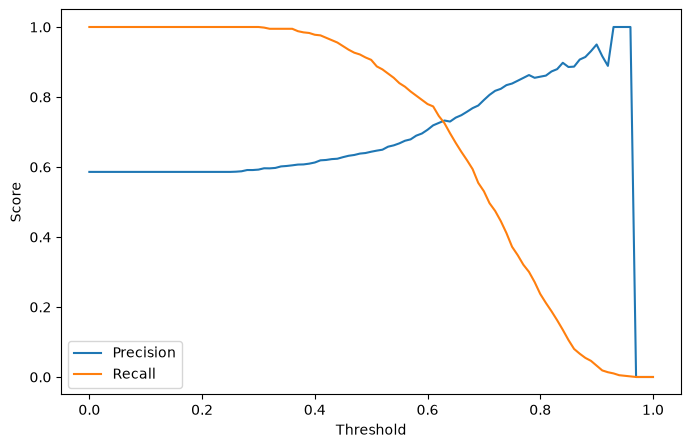

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

y_pred_val = model.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0, 1, 101)

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred_val >= t)
    predict_negative = (y_pred_val < t)
    
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    scores.append((t, precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

df_filtered = df_scores[(df_scores['precision'] > 0) | (df_scores['recall'] > 0)]

df_filtered['diff'] = abs(df_filtered['precision'] - df_filtered['recall'])
#idxmax() to git the number of indexthe best f1 score

best_row = df_filtered.loc[df_filtered['diff'].idxmin()]

print(best_row)

plt.figure(figsize=(8, 5))
plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()

In [80]:
denominator = df_scores['precision'] + df_scores['recall']
df_scores['f1'] = np.where(
    denominator > 0, 
    (2 * df_scores['precision'] * df_scores['recall']) / denominator, 
    0
)

#idxmax() to git the number of indexthe best f1 score
best_f1_row = df_scores.loc[df_scores['f1'].idxmax()]

print(best_f1_row)

from sklearn.metrics import f1_score,recall_score,precision_score

f1_results = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    y_pred_bin = (y_pred_val >= t).astype(int)
    
    score = f1_score(y_val, y_pred_bin, zero_division=0)
    
    f1_results.append({'threshold': t, 'f1': score})

df_f1 = pd.DataFrame(f1_results)
#idxmax() to git the number of indexthe best f1 score
best_f1_row = df_f1.loc[df_f1['f1'].idxmax()]

print(best_f1_row)

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64
threshold    0.410000
f1           0.757616
Name: 41, dtype: float64


In [81]:
from sklearn.model_selection import KFold

In [82]:
n_splits = 5
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

In [104]:


scores = []

df_full_train = df_full_train.reset_index(drop=True)
y_full_train = df_full_train.converted

X_full = df_full_train.drop(columns=['converted'])

for train_idx, val_idx in kfold.split(X_full):

    df_train_fold = X_full.iloc[train_idx]
    df_val_fold = X_full.iloc[val_idx]
    
    y_train_fold = y_full_train.iloc[train_idx]
    y_val_fold = y_full_train.iloc[val_idx]
    

    train_dicts_fold = df_train_fold[category + numirical].to_dict(orient='records')
    val_dicts_fold = df_val_fold[category + numirical].to_dict(orient='records')
    
    dv_fold = DictVectorizer(sparse=False)
    X_train_fold = dv_fold.fit_transform(train_dicts_fold)
    X_val_fold = dv_fold.transform(val_dicts_fold)
    
    model_fold = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model_fold.fit(X_train_fold, y_train_fold)
    
    y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]
    auc = roc_auc_score(y_val_fold, y_pred_fold)
    scores.append(auc)

std_deviation = np.std(scores)

print( [round(s, 4) for s in scores])
std_deviation

[0.7306, 0.7296, 0.7363, 0.7412, 0.7209]


np.float64(0.006853233151022138)

In [105]:
from sklearn.model_selection import KFold



In [ ]:
C_values = [0.000001, 0.001, 1]
tuning_results = {}

for C in C_values:
    scores_c = []
    for train_idx, val_idx in kfold.split(X_full):
        df_train_fold, df_val_fold = X_full.iloc[train_idx], X_full.iloc[val_idx]
        y_train_fold, y_val_fold = y_full_train.iloc[train_idx], y_full_train.iloc[val_idx]
        
        train_dicts = df_train_fold[category + numirical].to_dict(orient='records')
        val_dicts = df_val_fold[category + numirical].to_dict(orient='records')
        
        X_train_fold = dv.transform(train_dicts)
        X_val_fold = dv.transform(val_dicts)
        
        model.set_params(C=C)
        model.fit(X_train_fold, y_train_fold)
        
        y_pred_fold = model.predict_proba(X_val_fold)[:, 1]
        scores_c.append(roc_auc_score(y_val_fold, y_pred_fold))
    
    mean_auc, std_auc = round(np.mean(scores_c), 3), round(np.std(scores_c), 3)
    tuning_results[C] = {'mean': mean_auc, 'std': std_auc}
    C, mean_auc, std_auc
    

In [109]:
C,mean_auc,std_auc

(1, np.float64(0.732), np.float64(0.007))